In [159]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import IterativeImputer

### Définition de la classe 'MyLinearRegression', prenant comme paramètre 'with_b', où ce dernier est une variable booléenne.

In [173]:
class MyLinearRegression:
    def __init__(self, with_b=True):
        self.with_b = with_b
        self.weights = None

    def fit(self, X, y):
        # Ajouter une colonne de 1 pour l'intercept si nécessaire
        if self.with_b:
            X = np.c_[np.ones(X.shape[0]), X]

        # Assurez-vous que y est une colonne
        y = np.array(y).reshape(-1, 1)

        self.weights = np.linalg.inv(np.dot(X.T, X)).dot(X.T).dot(y)

    def predict(self, X):
        if self.with_b:
            X = np.c_[np.ones(X.shape[0]), X]

        return np.dot(X, self.weights)

>La classe MyLinearRegression représente un modèle de régression linéaire. Lors de son initialisation, le paramètre optionnel with_b (par défaut à True) permet de spécifier si le terme d'interception doit être inclus dans le modèle. La méthode fit ajuste les poids du modèle en fonction des données d'entraînement, et la méthode predict effectue des prédictions en utilisant ces poids, avec ou sans le terme d'interception en fonction de la valeur de with_b.

### Définition de la classe 'MyRidgeRegression', prenant comme paramètre 'with_b', où ce dernier est une variable booléenne.

In [174]:
class MyRidgeRegression:
    def __init__(self, with_b=True, alpha=0.0):
        self.with_b = with_b
        self.alpha = alpha
        self.weights = None

    def fit(self, X, y):
        if self.with_b:
            X = np.c_[np.ones(X.shape[0]), X]

        # Calculer les poids avec la régularisation ridge (équation normale avec L2)
        identity_matrix = np.eye(X.shape[1])
        ridge_term = self.alpha * identity_matrix
        self.weights = np.dot(np.linalg.inv(np.dot(X.T, X) + ridge_term), np.dot(X.T, y))

    def predict(self, X):
        if self.with_b:
            X = np.c_[np.ones(X.shape[0]), X]

        return np.dot(X, self.weights)


>La classe MyRidgeRegression est un modèle de régression ridge. Lors de l'initialisation, le paramètre optionnel with_b (par défaut à True) contrôle l'inclusion du terme d'interception, et alpha (par défaut à 0.0) règle la force de la régularisation ridge.

In [175]:
df = pd.read_csv('/content/Train.csv')
df.head()

,ID,District,Block,CultLand,CropCultLand,LandPreparationMethod,CropTillageDate,CropTillageDepth,CropEstMethod,RcNursEstDate,...,Harv_method,Harv_date,Harv_hand_rent,Threshing_date,Threshing_method,Residue_length,Residue_perc,Stubble_use,Acre,Yield
0,ID_GTFAC7PEVWQ9,Nalanda,Noorsarai,45,40,TractorPlough FourWheelTracRotavator,2022-07-20,5,Manual_PuddledRandom,2022-06-27,...,machine,2022-11-16,NaN,2022-11-16,machine,30,40,plowed_in_soil,0.312500,600
1,ID_TK40ARLSPOKS,Nalanda,Rajgir,26,26,WetTillagePuddling TractorPlough FourWheelTrac...,2022-07-18,5,Manual_PuddledRandom,2022-06-20,...,hand,2022-11-25,3.0,2022-12-24,machine,24,10,plowed_in_soil,0.312500,600
2,ID_1FJY2CRIMLZZ,Gaya,Gurua,10,10,TractorPlough FourWheelTracRotavator,2022-06-30,6,Manual_PuddledRandom,2022-06-20,...,hand,2022-12-12,480.0,2023-01-11,machine,30,10,plowed_in_soil,0.148148,225
3,ID_I3IPXS4DB7NE,Gaya,Gurua,15,15,TractorPlough FourWheelTracRotavator,2022-06-16,6,Manual_PuddledRandom,2022-06-17,...,hand,2022-12-02,240.0,2022-12-29,hand,26,10,plowed_in_soil,0.222222,468
4,ID_4T8YQWXWHB4A,Nalanda,Noorsarai,60,60,TractorPlough WetTillagePuddling,2022-07-19,4,Manual_PuddledRandom,2022-06-21,...,machine,2022-11-30,NaN,2022-12-02,machine,24,40,plowed_in_soil,0.468750,550


In [178]:
# Séparer les données en features (X) et target (y)
X = df.drop(['ID', 'Yield'], axis=1)
X = X.select_dtypes(include=np.number)
y = df['Yield']
imputer = IterativeImputer(random_state=0)
X = imputer.fit_transform(X)

# Avec b
regression_b = MyLinearRegression(with_b=True)
regression_b.fit(X, y)
predictions_b = regression_b.predict(X)
# Affichage des résultats
print("Avec intercept (b):")
dataframe_b = pd.DataFrame(predictions_b, columns=['Yield'])
print(dataframe_b.head())

# Sans b
regression = MyLinearRegression(with_b=False)
regression.fit(X, y)
predictions = regression.predict(X)
# Affichage des résultats
print("Sans intercept (b):")
dataframe = pd.DataFrame(predictions, columns=['Yield'])
print(dataframe.head())

Avec intercept (b):
        Yield
0  575.508950
1  625.395203
2  239.546493
3  597.382385
4  887.704513
Sans intercept (b):
        Yield
0  575.825585
1  625.106362
2  239.989678
3  597.176256
4  887.726614


/usr/local/lib/python3.10/dist-packages/sklearn/impute/_iterative.py:785: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


In [179]:
# Avec b
ridge_b = MyRidgeRegression(with_b=True)
ridge_b.fit(X, y)
ridgepredictions_b = ridge_b.predict(X)
# Affichage des résultats
print("Avec intercept (b):")
dataframe_b = pd.DataFrame(ridgepredictions_b, columns=['Yield'])
print(dataframe_b.head())

# Sans b
ridge = MyRidgeRegression(with_b=False)
ridge.fit(X, y)
ridgepredictions = ridge.predict(X)
# Affichage des résultats
print("Sans intercept (b):")
dataframe = pd.DataFrame(ridgepredictions, columns=['Yield'])
print(dataframe.head())

Avec intercept (b):
        Yield
0  575.508950
1  625.395203
2  239.546493
3  597.382385
4  887.704513
Sans intercept (b):
        Yield
0  575.825585
1  625.106362
2  239.989678
3  597.176256
4  887.726614


### Analyse de la Fréquence des Premiers Chiffres Extraits et Interprétation

In [192]:
def process_and_plot_frequency(input_list):
    def extract_first_digit(item):
        if isinstance(item, (int, float, np.number)):
            digits = str(item)
        elif isinstance(item, str):
            digits = ''.join(filter(str.isdigit, item))
        else:
            return None

        return digits[0] if digits else None

    # Filtrer et extraire les premiers chiffres
    digits_list = [extract_first_digit(item) for item in input_list if extract_first_digit(item) is not (None or '0')]

    # Calculer la fréquence des chiffres
    unique_digits, counts = np.unique(digits_list, return_counts=True)
    frequency_data = {'Digit': unique_digits, 'Frequency': counts}
    frequency_df = pd.DataFrame(frequency_data)

    plt.figure(figsize=(12, 5))
    sns.barplot(x='Digit', y='Frequency', data=frequency_df, palette="viridis")
    plt.title("Proportion de Premiers Chiffres Extraits par Élément")
    plt.xlabel("Chiffres")
    plt.ylabel("Fréquence")
    plt.show()

    print("Interprétation des résultats :")
    for digit, freq in zip(unique_digits, counts):
        print(f"Le chiffre {digit} apparaît {freq} fois.")

    most_frequent_digit = unique_digits[np.argmax(counts)]
    print(f"Le chiffre le plus fréquent est le {most_frequent_digit}. Il apparaît {np.max(counts)} fois.\n\n")

>La fonction process_and_plot_frequency prend une liste en entrée, extrait les premiers chiffres de chaque élément, puis crée un graphique de fréquence avec Seaborn. Enfin, elle affiche la liste des chiffres extraits, la fréquence de chaque chiffre, et identifie le chiffre le plus fréquent.

TROVIT


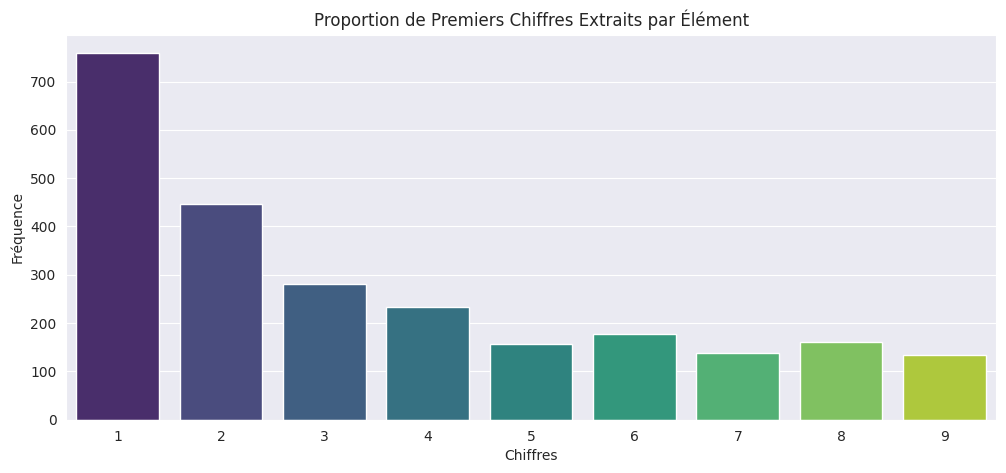

Interprétation des résultats :
Le chiffre 1 apparaît 759 fois.
Le chiffre 2 apparaît 446 fois.
Le chiffre 3 apparaît 281 fois.
Le chiffre 4 apparaît 233 fois.
Le chiffre 5 apparaît 157 fois.
Le chiffre 6 apparaît 177 fois.
Le chiffre 7 apparaît 139 fois.
Le chiffre 8 apparaît 161 fois.
Le chiffre 9 apparaît 135 fois.
Le chiffre le plus fréquent est le 1. Il apparaît 759 fois.


SAHOMETRADERS


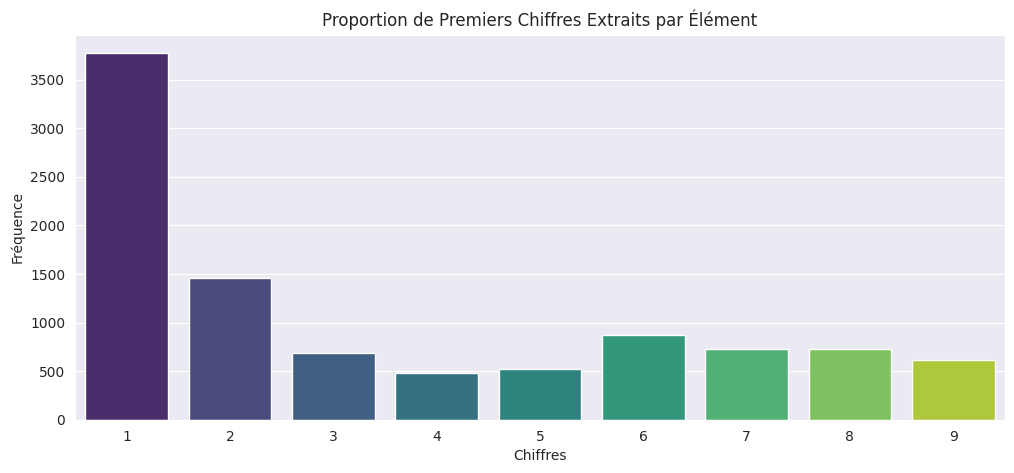

Interprétation des résultats :
Le chiffre 1 apparaît 3774 fois.
Le chiffre 2 apparaît 1462 fois.
Le chiffre 3 apparaît 682 fois.
Le chiffre 4 apparaît 485 fois.
Le chiffre 5 apparaît 519 fois.
Le chiffre 6 apparaît 868 fois.
Le chiffre 7 apparaît 724 fois.
Le chiffre 8 apparaît 727 fois.
Le chiffre 9 apparaît 610 fois.
Le chiffre le plus fréquent est le 1. Il apparaît 3774 fois.


REMAX


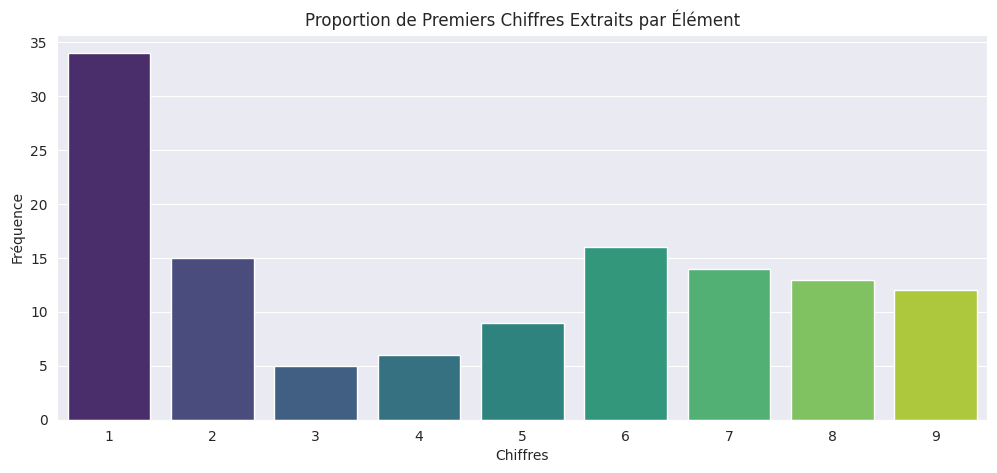

Interprétation des résultats :
Le chiffre 1 apparaît 34 fois.
Le chiffre 2 apparaît 15 fois.
Le chiffre 3 apparaît 5 fois.
Le chiffre 4 apparaît 6 fois.
Le chiffre 5 apparaît 9 fois.
Le chiffre 6 apparaît 16 fois.
Le chiffre 7 apparaît 14 fois.
Le chiffre 8 apparaît 13 fois.
Le chiffre 9 apparaît 12 fois.
Le chiffre le plus fréquent est le 1. Il apparaît 34 fois.


RAWSON


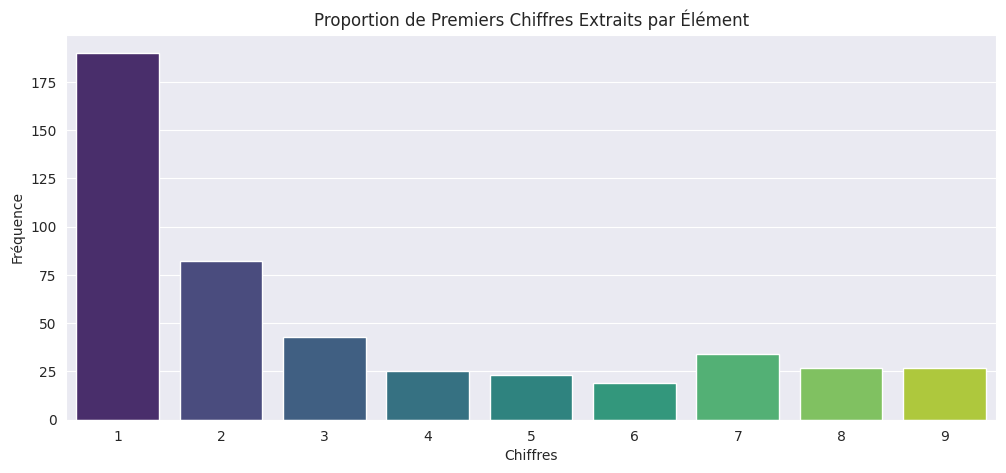

Interprétation des résultats :
Le chiffre 1 apparaît 190 fois.
Le chiffre 2 apparaît 82 fois.
Le chiffre 3 apparaît 43 fois.
Le chiffre 4 apparaît 25 fois.
Le chiffre 5 apparaît 23 fois.
Le chiffre 6 apparaît 19 fois.
Le chiffre 7 apparaît 34 fois.
Le chiffre 8 apparaît 27 fois.
Le chiffre 9 apparaît 27 fois.
Le chiffre le plus fréquent est le 1. Il apparaît 190 fois.


PROPERTY


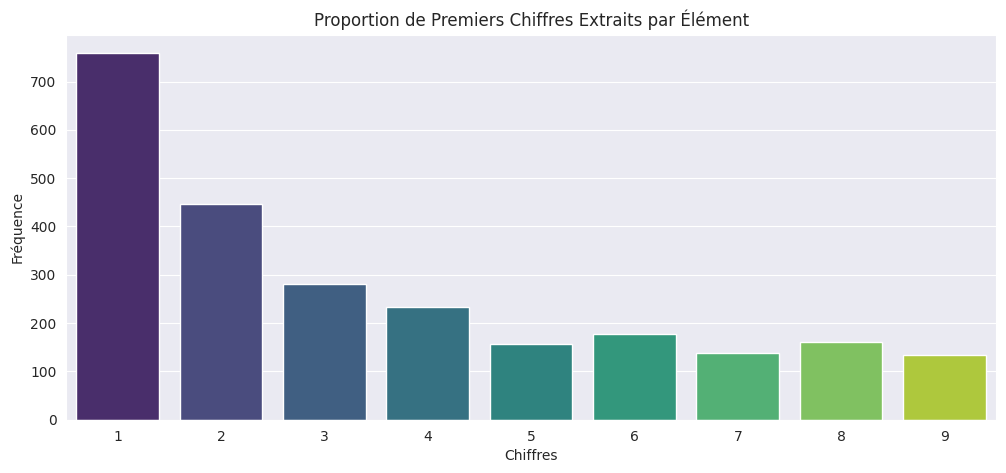

Interprétation des résultats :
Le chiffre 1 apparaît 759 fois.
Le chiffre 2 apparaît 446 fois.
Le chiffre 3 apparaît 281 fois.
Le chiffre 4 apparaît 233 fois.
Le chiffre 5 apparaît 157 fois.
Le chiffre 6 apparaît 177 fois.
Le chiffre 7 apparaît 139 fois.
Le chiffre 8 apparaît 161 fois.
Le chiffre 9 apparaît 135 fois.
Le chiffre le plus fréquent est le 1. Il apparaît 759 fois.


AREA


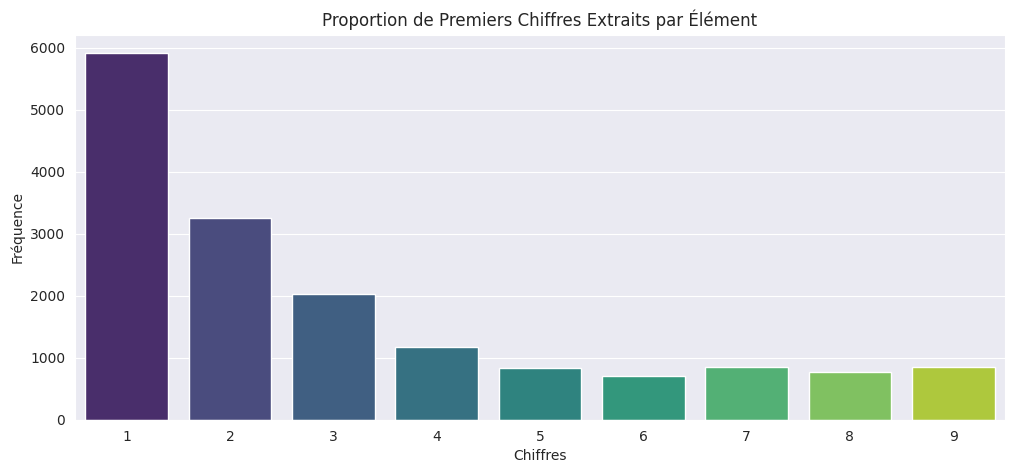

Interprétation des résultats :
Le chiffre 1 apparaît 5914 fois.
Le chiffre 2 apparaît 3251 fois.
Le chiffre 3 apparaît 2022 fois.
Le chiffre 4 apparaît 1176 fois.
Le chiffre 5 apparaît 827 fois.
Le chiffre 6 apparaît 709 fois.
Le chiffre 7 apparaît 852 fois.
Le chiffre 8 apparaît 769 fois.
Le chiffre 9 apparaît 851 fois.
Le chiffre le plus fréquent est le 1. Il apparaît 5914 fois.


PAMGOLDING


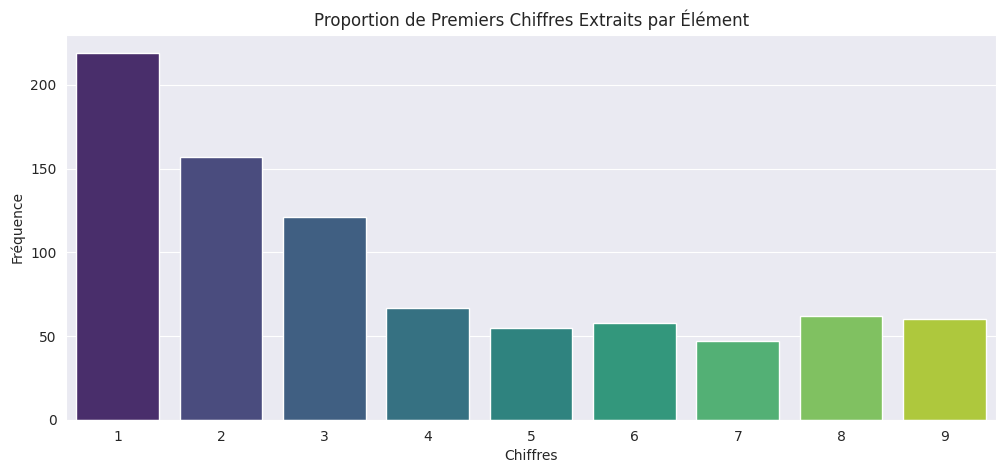

Interprétation des résultats :
Le chiffre 1 apparaît 219 fois.
Le chiffre 2 apparaît 157 fois.
Le chiffre 3 apparaît 121 fois.
Le chiffre 4 apparaît 67 fois.
Le chiffre 5 apparaît 55 fois.
Le chiffre 6 apparaît 58 fois.
Le chiffre 7 apparaît 47 fois.
Le chiffre 8 apparaît 62 fois.
Le chiffre 9 apparaît 60 fois.
Le chiffre le plus fréquent est le 1. Il apparaît 219 fois.




In [172]:
data = ['trovit', 'sahometraders', 'remax', 'rawson', 'property', 'area', 'pamgolding']
for d in data:
    df = pd.read_csv(f'/content/{d}.csv')
    try:
        df = df['Price']
    except:
        df = df['price']
    df = df.dropna().to_list()
    print(d.upper())
    process_and_plot_frequency(df)

Cases - cumulative total

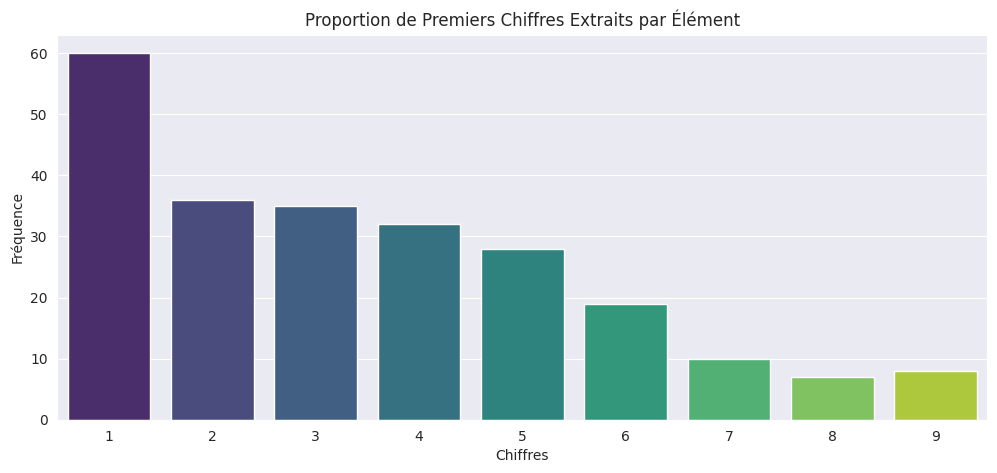

Interprétation des résultats :
Le chiffre 1 apparaît 60 fois.
Le chiffre 2 apparaît 36 fois.
Le chiffre 3 apparaît 35 fois.
Le chiffre 4 apparaît 32 fois.
Le chiffre 5 apparaît 28 fois.
Le chiffre 6 apparaît 19 fois.
Le chiffre 7 apparaît 10 fois.
Le chiffre 8 apparaît 7 fois.
Le chiffre 9 apparaît 8 fois.
Le chiffre le plus fréquent est le 1. Il apparaît 60 fois.




In [196]:
df = pd.read_csv('/content/WHO-COVID-19-global-table-data.csv')
df = df['Cases - cumulative total']
df = df.dropna().to_list()
process_and_plot_frequency(df)

Deaths - cumulative total

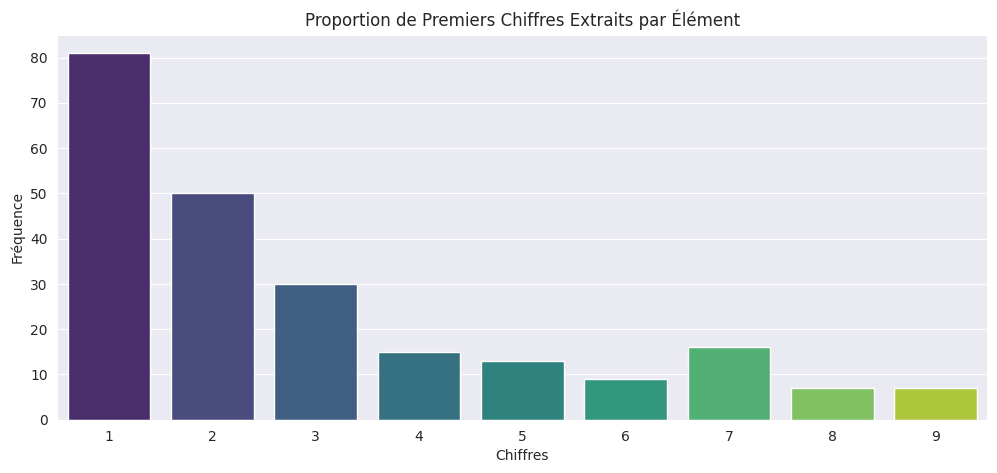

Interprétation des résultats :
Le chiffre 1 apparaît 81 fois.
Le chiffre 2 apparaît 50 fois.
Le chiffre 3 apparaît 30 fois.
Le chiffre 4 apparaît 15 fois.
Le chiffre 5 apparaît 13 fois.
Le chiffre 6 apparaît 9 fois.
Le chiffre 7 apparaît 16 fois.
Le chiffre 8 apparaît 7 fois.
Le chiffre 9 apparaît 7 fois.
Le chiffre le plus fréquent est le 1. Il apparaît 81 fois.




In [193]:
df = pd.read_csv('/content/WHO-COVID-19-global-table-data.csv')
df = df['Deaths - cumulative total']
df = df.dropna().to_list()
process_and_plot_frequency(df)

TOTAL_VACCINATIONS

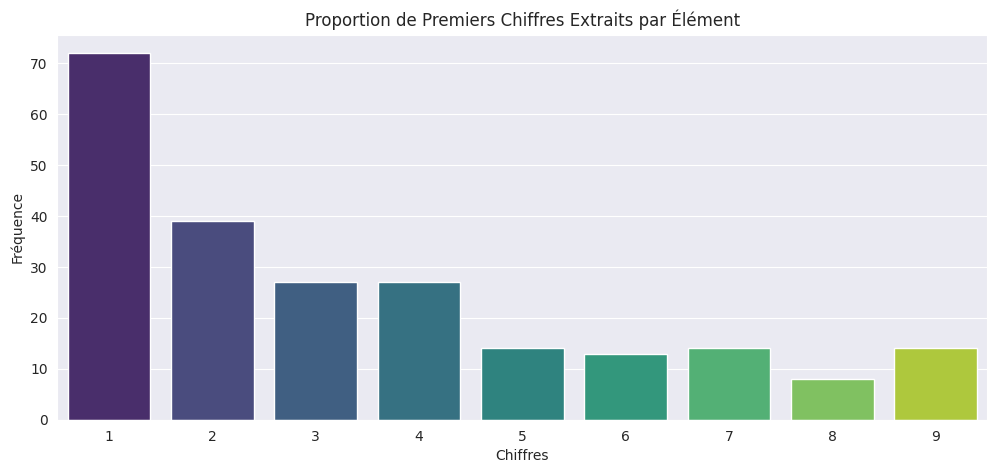

Interprétation des résultats :
Le chiffre 1 apparaît 72 fois.
Le chiffre 2 apparaît 39 fois.
Le chiffre 3 apparaît 27 fois.
Le chiffre 4 apparaît 27 fois.
Le chiffre 5 apparaît 14 fois.
Le chiffre 6 apparaît 13 fois.
Le chiffre 7 apparaît 14 fois.
Le chiffre 8 apparaît 8 fois.
Le chiffre 9 apparaît 14 fois.
Le chiffre le plus fréquent est le 1. Il apparaît 72 fois.




In [186]:
df = pd.read_csv('/content/vaccination-data.csv')
df = df['TOTAL_VACCINATIONS']
df = df.dropna().to_list()
process_and_plot_frequency(df)